# 🎓 SMARTEDU CRM -- DỰ ĐOÁN NGUY CƠ BỎ HỌC CẢNH BÁO SỚM (DROPOUT RISK v3)
### Trực quan hóa Từng bước Tiền xử lý, Kỹ nghệ Đặc trưng & Huấn luyện Pipeline Đạt chuẩn Kaggle

* **Mục tiêu:** Nhận diện sớm nguy cơ học viên bỏ học tại **mốc cảnh báo sớm** (Ngày thứ 30 / Cuối kỳ 1) để can thiệp kịp thời.
* **Nguồn dữ liệu thực tế:** $30.944$ lượt học từ **UCI** (Bồ Đào Nha) & **OULAD** (Đại học Mở Anh).
* **Cấu trúc Notebook:**
  * **Phần 1:** Thiết lập môi trường & Tham số.
  * **Phần 2:** Khám phá & Xử lý chi tiết dữ liệu **UCI** (Bóc tách thang điểm 20 $\rightarrow$ 10, loại bỏ Kỳ 2).
  * **Phần 3:** Khám phá & Xử lý chi tiết dữ liệu quan hệ **OULAD** (Lọc mốc Day 30, tính log click VLE và bài tập sớm).
  * **Phần 4:** Hợp nhất, Trực quan hóa EDA & Kiểm toán dữ liệu khuyết.
  * **Phần 5:** Chia tập Train/Test theo nhóm sinh viên (`StratifiedGroupKFold`).
  * **Phần 6:** Kiến trúc Pipeline với cờ `MissingIndicator`.
  * **Phần 7:** Đối chuẩn 5 mô hình trên Out-of-fold (OOF) PR-AUC & Tối ưu ngưỡng $F_2$-Score.
  * **Phần 8:** Đánh giá Hold-out Test, Bóc tách từng trường & Chuyển giao tri thức (Cross-Domain).
  * **Phần 9:** Tầm quan trọng đặc trưng & Dashboard trực quan.
  * **Phần 10:** Đóng gói Bundle sẵn sàng đưa vào Backend CRM.

## PHẦN 1: THIẾT LẬP MÔI TRƯỜNG & KHAI BÁO THAM SỐ

In [1]:
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import joblib

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 1000)

import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, brier_score_loss, confusion_matrix,
    fbeta_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve
)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Thiết lập thư mục làm việc
CURRENT_DIR = os.getcwd()
BASE_DIR = os.path.dirname(CURRENT_DIR) if 'ai_models' in CURRENT_DIR else CURRENT_DIR
UCI_PATH = os.path.join(BASE_DIR, 'dataset', 'archive', 'dropout_data_uci.csv')
OULAD_DIR = os.path.join(BASE_DIR, 'dataset', 'archive', 'dropout_data_OULAD')
REPORTS_DIR = os.path.join(CURRENT_DIR, 'reports_v3')
os.makedirs(REPORTS_DIR, exist_ok=True)

SEED = 42
CUTOFF_DAY = 30          # Mốc cảnh báo sớm cho OULAD (Tuần 4)
N_FOLDS = 5
TEST_FRAC = 0.20
KEYS = ['code_module', 'code_presentation', 'id_student']
TARGET_COL = 'Is_Dropout'

FEATURE_COLS = [
    'Attendance_Rate',                  # OULAD: Ngày active VLE / 31 | UCI: NaN
    'Consecutive_Unexcused_Absences',   # OULAD: Chuỗi ngày vắng liên tiếp | UCI: NaN
    'Days_Since_Last_Attended',         # OULAD: Số ngày ngừng tương tác đến Day 30 | UCI: NaN
    'Log_Total_Activity',               # OULAD: ln(1 + tổng clicks) | UCI: NaN
    'Assignment_Missing_Rate',          # Tỷ lệ bài tập / môn không nộp bài | Cả 2
    'Assignment_Late_Count',            # OULAD: Số bài nộp muộn hạn | UCI: NaN
    'Average_Score',                    # Điểm trung bình thang 10 | Cả 2
    'Score_Trend',                      # OULAD: Điểm bài sau - bài trước | UCI: NaN
    'Pass_Rate',                        # Tỷ lệ môn/bài đạt yêu cầu | Cả 2
    'Has_Overdue_Invoice'               # UCI: Nợ học phí hoặc quá hạn | OULAD: NaN
]
SHARED_FEATURES = ['Average_Score', 'Assignment_Missing_Rate', 'Pass_Rate']
print("[OK] Môi trường và tham số đã sẵn sàng!")

C:\Users\Thuong's Laptop\AppData\Local\Temp\ipykernel_6360\3751744782.py:6: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


[OK] Môi trường và tham số đã sẵn sàng!


## PHẦN 2: BÓC TÁCH VÀ TIỀN XỬ LÝ DỮ LIỆU UCI (BỒ ĐÀO NHA)

### 2.1. Khám phá dữ liệu thô UCI (Raw Data Inspection)
Xem cấu trúc ban đầu của file `dropout_data_uci.csv` ($4.424$ dòng, $37$ cột).

In [2]:
raw_uci = pd.read_csv(UCI_PATH, sep=';')
raw_uci.columns = [c.strip() for c in raw_uci.columns]
print(f"[*] Kích thước dữ liệu thô UCI: {raw_uci.shape}")
print(f"[*] Phân phối nhãn mục tiêu thô (Target):\n{raw_uci['Target'].value_counts(normalize=True).round(4) * 100}")

# Hiển thị các cột học thuật và tài chính quan trọng
inspect_cols = [
    'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)',
    'Debtor', 'Tuition fees up to date', 'Target'
]
raw_uci[inspect_cols].head(5)

[*] Kích thước dữ liệu thô UCI: (4424, 37)
[*] Phân phối nhãn mục tiêu thô (Target):
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64


,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (grade),Debtor,Tuition fees up to date,Target
0,0,0,0.000000,0.000000,0,1,Dropout
1,6,6,14.000000,13.666667,0,0,Graduate
2,6,0,0.000000,0.000000,0,0,Dropout
3,6,6,13.428571,12.400000,0,1,Graduate
4,6,5,12.333333,13.000000,0,1,Graduate


### 2.2. Xử lý Chống Rò Rỉ & Biến đổi Đặc trưng UCI
* **Vấn đề 1 (Rò rỉ Kỳ 2):** Cột `Curricular units 2nd sem (grade)` là điểm kỳ 2, chưa hề tồn tại khi sinh viên học kỳ 1 $\rightarrow$ **Loại bỏ $100\%$**.
* **Vấn đề 2 (Thang điểm):** Bồ Đào Nha dùng thang điểm $0 - 20$ $\rightarrow$ Ta chia cho $2.0$ để đưa về chuẩn $0 - 10$.
* **Vấn đề 3 (Nhãn nhị phân):** Loại bỏ nhóm `Enrolled` để ground-truth phân định rõ ràng giữa `Dropout` (1) và `Graduate` (0).

In [3]:
# 1. Lọc nhãn sạch nhị phân
clean_uci_raw = raw_uci[raw_uci['Target'].isin(['Dropout', 'Graduate'])].copy().reset_index(drop=True)

# 2. Chuyển đổi kiểu số cho các trường kỳ 1
enrolled = pd.to_numeric(clean_uci_raw['Curricular units 1st sem (enrolled)'], errors='coerce')
approved = pd.to_numeric(clean_uci_raw['Curricular units 1st sem (approved)'], errors='coerce')
grade_20 = pd.to_numeric(clean_uci_raw['Curricular units 1st sem (grade)'], errors='coerce')
without_eval = pd.to_numeric(clean_uci_raw['Curricular units 1st sem (without evaluations)'], errors='coerce')

# Lọc các bạn có đăng ký ít nhất 1 môn
keep = enrolled > 0
clean_uci_raw = clean_uci_raw[keep].reset_index(drop=True)
enrolled, approved, grade_20, without_eval = (x[keep].reset_index(drop=True) for x in (enrolled, approved, grade_20, without_eval))

# 3. Tính toán các đặc trưng chuẩn hóa
uci_df = pd.DataFrame(index=clean_uci_raw.index)
uci_df['Average_Score'] = np.where(approved > 0, np.clip(grade_20 / 2.0, 0, 10), np.nan)   # Thang điểm 10
uci_df['Pass_Rate'] = np.clip(approved / enrolled, 0, 1)                                   # Tỷ lệ hoàn thành
uci_df['Assignment_Missing_Rate'] = np.clip(without_eval / enrolled, 0, 1)                # Tỷ lệ bỏ thi
uci_df['Has_Overdue_Invoice'] = ((clean_uci_raw['Debtor'] == 1) | (clean_uci_raw['Tuition fees up to date'] == 0)).astype(float)

# Các cột VLE không có ở UCI -> Giữ nguyên NaN (Không chế số giả)
for col in FEATURE_COLS:
    if col not in uci_df:
        uci_df[col] = np.nan

uci_df[TARGET_COL] = (clean_uci_raw['Target'] == 'Dropout').astype(int)
uci_df['id_student'] = 'UCI_' + clean_uci_raw.index.astype(str)
uci_df['Data_Source'] = 'UCI'

# So sánh bảng TRƯỚC (thô) và SAU (chuẩn hóa)
print("=== BẢNG SO SÁNH: TRƯỚC VÀ SAU KHI TIỀN XỬ LÝ (UCI) ===")
comparison_uci = pd.DataFrame({
    'Raw_Grade_20': grade_20,
    'Clean_Score_10': uci_df['Average_Score'],
    'Raw_Enrolled': enrolled,
    'Raw_Approved': approved,
    'Clean_Pass_Rate': uci_df['Pass_Rate'],
    'Clean_Has_Debt': uci_df['Has_Overdue_Invoice'],
    'Target_Dropout': uci_df[TARGET_COL]
})
comparison_uci.head(5)

=== BẢNG SO SÁNH: TRƯỚC VÀ SAU KHI TIỀN XỬ LÝ (UCI) ===


,Raw_Grade_20,Clean_Score_10,Raw_Enrolled,Raw_Approved,Clean_Pass_Rate,Clean_Has_Debt,Target_Dropout
0,14.000000,7.000000,6,6,1.000000,1.0,0
1,0.000000,NaN,6,0,0.000000,1.0,1
2,13.428571,6.714286,6,6,1.000000,0.0,0
3,12.333333,6.166667,6,5,0.833333,0.0,0
4,11.857143,5.928571,5,5,1.000000,1.0,0


## PHẦN 3: BÓC TÁCH VÀ TIỀN XỬ LÝ DỮ LIỆU QUAN HỆ OULAD (ANH)

### 3.1. Khám phá các bảng quan hệ của OULAD
OULAD không phải 1 file duy nhất mà gồm nhiều bảng quan hệ:
1. `studentInfo.csv`: Thông tin sinh viên và kết quả chung cuộc (`final_result`).
2. `studentRegistration.csv`: Ngày sinh viên hủy môn/rút học (`date_unregistration`).
3. `assessments.csv` & `studentAssessment.csv`: Hạn nộp, điểm bài tập và ngày nộp thực tế.
4. `studentVle.csv` ($453$ MB, $10.6$ triệu dòng): Nhật ký click tài liệu và video theo từng ngày.

In [4]:
p = lambda f: os.path.join(OULAD_DIR, f)
raw_info = pd.read_csv(p('studentInfo.csv'), nrows=3)
raw_reg  = pd.read_csv(p('studentRegistration.csv'), nrows=3)
raw_ass  = pd.read_csv(p('assessments.csv'), nrows=3)
print("[*] Xem trước bảng studentInfo:")
display(raw_info[['code_module', 'code_presentation', 'id_student', 'final_result']])
print("[*] Xem trước bảng studentRegistration (chứa ngày hủy học date_unregistration):")
display(raw_reg)

[*] Xem trước bảng studentInfo:


,code_module,code_presentation,id_student,final_result
0,AAA,2013J,11391,Pass
1,AAA,2013J,28400,Pass
2,AAA,2013J,30268,Withdrawn


[*] Xem trước bảng studentRegistration (chứa ngày hủy học date_unregistration):


,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159,NaN
1,AAA,2013J,28400,-53,NaN
2,AAA,2013J,30268,-92,12.0


### 3.2. Áp dụng Mốc Cảnh Báo Sớm: Ngày thứ 30 (Cutoff Day = 30)
* **Vấn đề cốt lõi:** Khóa học dài 240 ngày. Nếu dùng dữ liệu của ngày thứ 150 để dự đoán thì đã quá muộn!
* **Luật lọc:**
  1. Sinh viên rút học TRƯỚC ngày 30 ($date\_unregistration \le 30$) $\rightarrow$ **Loại bỏ** (họ đã nghỉ trước mốc cảnh báo).
  2. Sinh viên còn học tại ngày 30 $\rightarrow$ Đưa vào theo dõi để dự đoán ai sẽ rút học sau đó (`Withdrawn` $\rightarrow$ 1, `Pass/Fail` $\rightarrow$ 0).

In [5]:
info = pd.read_csv(p('studentInfo.csv'))
reg  = pd.read_csv(p('studentRegistration.csv'))
enr = info.merge(reg[KEYS + ['date_unregistration']], on=KEYS, how='inner')
enr['date_unregistration'] = pd.to_numeric(enr['date_unregistration'], errors='coerce')

n_total = len(enr)
enr_active_day30 = enr[enr['date_unregistration'].isna() | (enr['date_unregistration'] > CUTOFF_DAY)].copy()
enr_active_day30[TARGET_COL] = (enr_active_day30['final_result'] == 'Withdrawn').astype(int)
enr_active_day30 = enr_active_day30[KEYS + [TARGET_COL]].drop_duplicates(KEYS).reset_index(drop=True)

print(f"[*] Tổng lượt đăng ký ban đầu : {n_total:,}")
print(f"[*] Số học viên đã nghỉ trước Day 30 (bị loại): {n_total - len(enr_active_day30):,}")
print(f"[*] Số học viên ĐANG HỌC TẠI DAY 30 (cần dự đoán): {len(enr_active_day30):,} | Tỉ lệ bỏ học sau đó: {enr_active_day30[TARGET_COL].mean():.2%}")

[*] Tổng lượt đăng ký ban đầu : 32,593
[*] Số học viên đã nghỉ trước Day 30 (bị loại): 5,127
[*] Số học viên ĐANG HỌC TẠI DAY 30 (cần dự đoán): 27,466 | Tỉ lệ bỏ học sau đó: 18.34%


### 3.3. Xử lý Điểm Bài Tập Sớm & Streaming Log Clicks VLE (Ngày $\le 30$)

In [6]:
# 1. Xử lý bài tập nộp trong 30 ngày đầu
asm = pd.read_csv(p('assessments.csv'))[['code_module', 'code_presentation', 'id_assessment', 'date']].rename(columns={'date': 'date_due'})
asm['date_due'] = pd.to_numeric(asm['date_due'], errors='coerce')
n_due = asm[asm['date_due'] <= CUTOFF_DAY].groupby(['code_module', 'code_presentation']).size().rename('n_due').reset_index()

sa = pd.read_csv(p('studentAssessment.csv'))
sa['score'] = pd.to_numeric(sa['score'], errors='coerce')
sa['date_submitted'] = pd.to_numeric(sa['date_submitted'], errors='coerce')
sa = sa.merge(asm, on='id_assessment', how='left')
sa_early = sa[sa['date_submitted'] <= CUTOFF_DAY].merge(enr_active_day30[KEYS], on=KEYS, how='inner').sort_values('date_submitted')
sa_early['is_late'] = ((sa_early['date_submitted'] > sa_early['date_due']) & sa_early['date_due'].notna()).astype(int)
sa_early['passed'] = np.where(sa_early['score'].notna(), (sa_early['score'] >= 40).astype(float), np.nan)

g_ass = sa_early.groupby(KEYS)
ass_feat = pd.DataFrame({
    'Average_Score': g_ass['score'].mean() / 10.0,
    'Pass_Rate': g_ass['passed'].mean(),
    'Assignment_Late_Count': g_ass['is_late'].sum(),
    '_first': g_ass['score'].first(),
    '_last': g_ass['score'].last(),
    '_n_scored': g_ass['score'].count(),
})
ass_feat['Score_Trend'] = np.where(ass_feat['_n_scored'] >= 2, (ass_feat['_last'] - ass_feat['_first']) / 10.0, np.nan)
ass_feat['_n_due_submitted'] = sa_early[sa_early['date_due'] <= CUTOFF_DAY].groupby(KEYS).size()
ass_feat = ass_feat.reset_index()

# 2. Stream log VLE (chỉ lấy date trong khoảng 0 đến 30)
print("[*] Đang stream đọc 10.6 triệu dòng VLE trong cửa sổ [0, 30] ngày...")
parts = []
for chunk in pd.read_csv(p('studentVle.csv'), usecols=KEYS + ['date', 'sum_click'], chunksize=1_000_000):
    chunk = chunk[(chunk['date'] >= 0) & (chunk['date'] <= CUTOFF_DAY)]
    if not chunk.empty:
        parts.append(chunk.groupby(KEYS + ['date'], as_index=False)['sum_click'].sum())

vle_early = pd.concat(parts).groupby(KEYS + ['date'], as_index=False)['sum_click'].sum()
vle_early = vle_early.merge(enr_active_day30[KEYS], on=KEYS, how='inner').sort_values(KEYS + ['date'])
prev = vle_early.groupby(KEYS)['date'].shift(1).fillna(-1)
vle_early['gap'] = vle_early['date'] - prev - 1

gv = vle_early.groupby(KEYS)
act_feat = pd.DataFrame({
    'n_active': gv['date'].nunique(),
    'last_active': gv['date'].max(),
    'clicks': gv['sum_click'].sum(),
    'max_gap': gv['gap'].max(),
}).reset_index()

# 3. Ghép thành bảng hoàn chỉnh OULAD mốc Day 30
window = CUTOFF_DAY + 1
df_oulad = enr_active_day30.merge(act_feat, on=KEYS, how='left').merge(ass_feat, on=KEYS, how='left').merge(n_due, on=['code_module', 'code_presentation'], how='left')
df_oulad['n_active'] = df_oulad['n_active'].fillna(0)
df_oulad['clicks'] = df_oulad['clicks'].fillna(0)
df_oulad['Attendance_Rate'] = df_oulad['n_active'] / window
df_oulad['Consecutive_Unexcused_Absences'] = np.where(df_oulad['n_active'] > 0, np.maximum(df_oulad['max_gap'], CUTOFF_DAY - df_oulad['last_active']), window)
df_oulad['Days_Since_Last_Attended'] = np.where(df_oulad['n_active'] > 0, CUTOFF_DAY - df_oulad['last_active'], window)
df_oulad['Log_Total_Activity'] = np.log1p(df_oulad['clicks'])
df_oulad['Assignment_Late_Count'] = df_oulad['Assignment_Late_Count'].fillna(0)
sub = df_oulad['_n_due_submitted'].fillna(0)
df_oulad['Assignment_Missing_Rate'] = np.where(df_oulad['n_due'] > 0, np.clip(1.0 - sub / df_oulad['n_due'].replace(0, np.nan), 0, 1), np.nan)
df_oulad['Has_Overdue_Invoice'] = np.nan
df_oulad['id_student'] = df_oulad['id_student'].astype(str)
df_oulad['Data_Source'] = 'OULAD'

oulad_df = df_oulad[FEATURE_COLS + [TARGET_COL, 'id_student', 'Data_Source']].reset_index(drop=True)
print(f"[OK] Hoàn tất trích xuất đặc trưng OULAD: {len(oulad_df):,} bản ghi!")
oulad_df[['Attendance_Rate', 'Days_Since_Last_Attended', 'Log_Total_Activity', 'Average_Score', 'Pass_Rate', 'Is_Dropout']].head(5)

[*] Đang stream đọc 10.6 triệu dòng VLE trong cửa sổ [0, 30] ngày...
[OK] Hoàn tất trích xuất đặc trưng OULAD: 27,466 bản ghi!


,Attendance_Rate,Days_Since_Last_Attended,Log_Total_Activity,Average_Score,Pass_Rate,Is_Dropout
0,0.290323,0.0,5.789960,7.8,1.0,0
1,0.387097,2.0,6.001415,7.0,1.0,0
2,0.612903,0.0,5.918894,7.2,1.0,0
3,0.516129,4.0,5.609472,6.9,1.0,0
4,0.774194,0.0,6.118097,7.9,1.0,0


## PHẦN 4: HỢP NHẤT DỮ LIỆU & KIỂM TOÁN KHUYẾT THIẾU (DATA FUSION & EDA)

In [7]:
final_df = pd.concat([uci_df, oulad_df], ignore_index=True).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
print(f"[*] Tổng số bản ghi hỗn hợp: {len(final_df):,} | Tỉ lệ bỏ học chung: {final_df[TARGET_COL].mean():.2%}")

# Kiểm toán tỷ lệ khuyết thiếu của từng đặc trưng
missing_audit = pd.DataFrame({
    'Tên Đặc Trưng': FEATURE_COLS,
    'Số lượng khuyết': final_df[FEATURE_COLS].isna().sum().values,
    'Tỷ lệ khuyết (%)': (final_df[FEATURE_COLS].isna().mean() * 100).round(2).values,
    'Ý nghĩa học thuật': [
        'Chỉ có ở OULAD (VLE logs)', 'Chỉ có ở OULAD (VLE logs)', 'Chỉ có ở OULAD (VLE logs)', 'Chỉ có ở OULAD (VLE logs)',
        'Có ở cả 2 nguồn (Khuyết nếu SV không có bài tập)', 'Chỉ có ở OULAD',
        'Có ở cả 2 nguồn (Khuyết nếu SV chưa có điểm bài đầu)', 'Chỉ có ở OULAD (cần ít nhất 2 bài)',
        'Có ở cả 2 nguồn', 'Chỉ có ở UCI (thông tin tài chính)'
    ]
})
missing_audit

[*] Tổng số bản ghi hỗn hợp: 30,944 | Tỉ lệ bỏ học chung: 20.62%


,Tên Đặc Trưng,Số lượng khuyết,Tỷ lệ khuyết (%),Ý nghĩa học thuật
0,Attendance_Rate,3478,11.24,Chỉ có ở OULAD (VLE logs)
1,Consecutive_Unexcused_Absences,3478,11.24,Chỉ có ở OULAD (VLE logs)
2,Days_Since_Last_Attended,3478,11.24,Chỉ có ở OULAD (VLE logs)
3,Log_Total_Activity,3478,11.24,Chỉ có ở OULAD (VLE logs)
4,Assignment_Missing_Rate,4987,16.12,Có ở cả 2 nguồn (Khuyết nếu SV không có bài tập)
5,Assignment_Late_Count,3478,11.24,Chỉ có ở OULAD
6,Average_Score,7113,22.99,Có ở cả 2 nguồn (Khuyết nếu SV chưa có điểm bà...
7,Score_Trend,27321,88.29,Chỉ có ở OULAD (cần ít nhất 2 bài)
8,Pass_Rate,6618,21.39,Có ở cả 2 nguồn
9,Has_Overdue_Invoice,27466,88.76,Chỉ có ở UCI (thông tin tài chính)


## PHẦN 5: CHIA TẬP TRAIN/TEST THEO NHÓM SINH VIÊN (`StratifiedGroupKFold`)

Đảm bảo nguyên tắc vàng: **Không có sinh viên nào xuất hiện đồng thời ở cả Train và Test**.

In [8]:
strat = final_df[TARGET_COL].astype(str) + '_' + final_df['Data_Source']
sgkf = StratifiedGroupKFold(n_splits=int(round(1 / TEST_FRAC)), shuffle=True, random_state=SEED)
tr_idx, te_idx = next(sgkf.split(final_df, strat, groups=final_df['id_student']))

train_df = final_df.iloc[tr_idx].reset_index(drop=True)
test_df  = final_df.iloc[te_idx].reset_index(drop=True)

# Assert check chống rò rỉ
overlap = set(train_df['id_student']).intersection(set(test_df['id_student']))
assert len(overlap) == 0, "LỖI: Phát hiện trùng lặp sinh viên giữa Train và Test!"

print(f"[*] Tập Train: {len(train_df):,} dòng ({train_df['id_student'].nunique():,} sinh viên) | Bỏ học: {train_df[TARGET_COL].mean():.2%}")
print(f"[*] Tập Test : {len(test_df):,} dòng ({test_df['id_student'].nunique():,} sinh viên) | Bỏ học: {test_df[TARGET_COL].mean():.2%}")

[*] Tập Train: 24,738 dòng (22,610 sinh viên) | Bỏ học: 20.81%
[*] Tập Test : 6,206 dòng (5,655 sinh viên) | Bỏ học: 19.85%


## PHẦN 6: THIẾT KẾ PIPELINE TỰ ĐỘNG HÓA VỚI MISSING INDICATOR

In [9]:
def make_pipeline(clf, features):
    prep = ColumnTransformer([
        ('num', Pipeline([
            ('imp', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
            ('sc', StandardScaler()),
        ]), features)
    ])
    return Pipeline([('prep', prep), ('clf', clf)])

def model_zoo():
    return {
        'Dummy (prior)': DummyClassifier(strategy='prior'),
        'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=2000, random_state=SEED),
        'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight='balanced', random_state=SEED),
        'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5, class_weight='balanced_subsample', random_state=SEED, n_jobs=-1),
        'HistGradientBoosting': HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, l2_regularization=1.0, class_weight='balanced', random_state=SEED),
    }
print("[OK] Pipeline factory đã định nghĩa 5 mô hình cơ sở.")

[OK] Pipeline factory đã định nghĩa 5 mô hình cơ sở.


## PHẦN 7: HUẤN LUYỆN ĐỐI CHUẨN ĐA MÔ HÌNH & TỐI ƯU NGƯỠNG $F_2$-SCORE

In [10]:
def best_threshold(y, p, beta=2.0):
    pr, rc, th = precision_recall_curve(y, p)
    pr, rc = pr[:-1], rc[:-1]
    f = (1 + beta ** 2) * pr * rc / np.maximum(beta ** 2 * pr + rc, 1e-12)
    return float(th[int(np.argmax(f))]) if len(th) else 0.5

def evaluate(y, p, thr):
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= thr).astype(int)
    one_class = len(np.unique(y)) < 2
    return {
        'roc_auc': None if one_class else round(float(roc_auc_score(y, p)), 4),
        'pr_auc': None if one_class else round(float(average_precision_score(y, p)), 4),
        'threshold': round(float(thr), 4),
        'precision': round(float(precision_score(y, pred, zero_division=0)), 4),
        'recall': round(float(recall_score(y, pred, zero_division=0)), 4),
        'f1': round(float(fbeta_score(y, pred, beta=1, zero_division=0)), 4),
        'f2': round(float(fbeta_score(y, pred, beta=2, zero_division=0)), 4),
        'brier': round(float(brier_score_loss(y, p)), 4),
    }

Xtr, ytr, gtr = train_df[FEATURE_COLS], train_df[TARGET_COL].values, train_df['id_student']
Xte, yte = test_df[FEATURE_COLS], test_df[TARGET_COL].values

results, fitted, test_prob, oof_ap = {}, {}, {}, {}
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

print("[*] Đang chạy 5-Fold Cross-Validation và đánh giá Out-of-fold trên tập Train...")
for name, clf in model_zoo().items():
    pipe = make_pipeline(clf, FEATURE_COLS)
    oof = cross_val_predict(pipe, Xtr, ytr, cv=cv, groups=gtr, method='predict_proba', n_jobs=-1)[:, 1]
    thr = best_threshold(ytr, oof)
    oof_ap[name] = float(average_precision_score(ytr, oof))
    pipe.fit(Xtr, ytr)
    prob = pipe.predict_proba(Xte)[:, 1]
    fitted[name], test_prob[name] = pipe, prob
    results[name] = {
        'OOF_PR_AUC': round(oof_ap[name], 4),
        **evaluate(yte, prob, thr)
    }

best_name = max({k: v for k, v in oof_ap.items() if not k.startswith('Dummy')}, key=oof_ap.get)
best_thr = results[best_name]['threshold']
print(f"\n[KẾT QUẢ] Mô hình chiến thắng: {best_name} (OOF PR-AUC = {oof_ap[best_name]:.4f}, Ngưỡng tối ưu = {best_thr:.4f})")
pd.DataFrame(results).T[['OOF_PR_AUC', 'roc_auc', 'pr_auc', 'recall', 'precision', 'f2', 'brier']]

[*] Đang chạy 5-Fold Cross-Validation và đánh giá Out-of-fold trên tập Train...


  File "d:\KiemTra\Hoc_ky_8\DACN_3\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^



[KẾT QUẢ] Mô hình chiến thắng: HistGradientBoosting (OOF PR-AUC = 0.5342, Ngưỡng tối ưu = 0.3401)


,OOF_PR_AUC,roc_auc,pr_auc,recall,precision,f2,brier
Dummy (prior),0.2032,0.5000,0.1985,1.0000,0.1985,0.5533,0.1592
Logistic Regression,0.4771,0.6998,0.4473,0.8994,0.2305,0.5691,0.2065
Decision Tree,0.5155,0.7189,0.4847,0.9351,0.2151,0.5601,0.1945
Random Forest,0.5310,0.7304,0.5074,0.8620,0.2482,0.5768,0.1877
HistGradientBoosting,0.5342,0.7289,0.5065,0.8709,0.2455,0.5769,0.1939


## PHẦN 8: BÓC TÁCH TỪNG TRƯỜNG & CHUYỂN GIAO TRI THỨC (CROSS-DOMAIN)

In [11]:
# 1. Đánh giá riêng biệt trên Test Set của từng trường
per_source = {}
for src in ['OULAD', 'UCI']:
    m = (test_df['Data_Source'] == src).values
    per_source[src] = evaluate(yte[m], test_prob[best_name][m], best_thr)
print("[*] Đánh giá theo từng trường đào tạo (Per-Source Test Performance):")
display(pd.DataFrame(per_source).T[['roc_auc', 'pr_auc', 'recall', 'precision', 'f2']])

# 2. Thử nghiệm chuyển giao tri thức liên trường (Cross-Domain Test)
uci, oul = final_df[final_df['Data_Source'] == 'UCI'], final_df[final_df['Data_Source'] == 'OULAD']
rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5, class_weight='balanced_subsample', random_state=SEED, n_jobs=-1)

def transfer(src, dst):
    pipe = make_pipeline(clone(rf), SHARED_FEATURES).fit(src[SHARED_FEATURES], src[TARGET_COL])
    pr = pipe.predict_proba(dst[SHARED_FEATURES])[:, 1]
    return {'ROC_AUC': round(float(roc_auc_score(dst[TARGET_COL], pr)), 4), 'PR_AUC': round(float(average_precision_score(dst[TARGET_COL], pr)), 4)}

cd_df = pd.DataFrame({
    'OULAD -> UCI (Online sang Truyền thống)': transfer(oul, uci),
    'UCI -> OULAD (Truyền thống sang Online)': transfer(uci, oul)
}).T
print("\n[*] Khả năng chuyển giao tri thức khi chỉ dùng 3 đặc trưng học tập chung (Pass_Rate, Missing_Rate, Score):")
display(cd_df)

[*] Đánh giá theo từng trường đào tạo (Per-Source Test Performance):


,roc_auc,pr_auc,recall,precision,f2
OULAD,0.6781,0.3437,0.8618,0.2138,0.5366
UCI,0.9163,0.9032,0.9087,0.5778,0.8153



[*] Khả năng chuyển giao tri thức khi chỉ dùng 3 đặc trưng học tập chung (Pass_Rate, Missing_Rate, Score):


,ROC_AUC,PR_AUC
OULAD -> UCI (Online sang Truyền thống),0.7842,0.6953
UCI -> OULAD (Truyền thống sang Online),0.6022,0.2556


## PHẦN 9: TẦM QUAN TRỌNG ĐẶC TRƯNG & DASHBOARD ĐỒ HỌA BÁO CÁO

In [12]:
# Tính Permutation Importance trên tập Test
pi = permutation_importance(fitted[best_name], Xte, yte, scoring='average_precision', n_repeats=5, random_state=SEED, n_jobs=-1)
imp_dict = dict(sorted(zip(FEATURE_COLS, pi.importances_mean.round(4).tolist()), key=lambda kv: -kv[1]))

# Vẽ Dashboard tổng hợp 4 trong 1
fig, ax = plt.subplots(2, 2, figsize=(14, 11), dpi=150)

# Subplot A: ROC
for name, p in test_prob.items():
    if len(np.unique(p)) > 1:
        fpr, tpr, _ = roc_curve(yte, p)
        ax[0, 0].plot(fpr, tpr, lw=2.2 if name == best_name else 1.2, label=f"{name} ({roc_auc_score(yte, p):.3f})")
ax[0, 0].plot([0, 1], [0, 1], 'k:')
ax[0, 0].set(title='(A) Đường cong ROC-AUC so sánh 5 mô hình', xlabel='False Positive Rate', ylabel='True Positive Rate')
ax[0, 0].legend(loc='lower right', fontsize=8)

# Subplot B: PR Curve
for name, p in test_prob.items():
    if len(np.unique(p)) > 1:
        pr, rc, _ = precision_recall_curve(yte, p)
        ax[0, 1].plot(rc, pr, lw=2.2 if name == best_name else 1.2, label=f"{name} ({average_precision_score(yte, p):.3f})")
ax[0, 1].axhline(np.mean(yte), color='gray', ls=':', label=f'Tỷ lệ ngẫu nhiên ({np.mean(yte):.1%})')
ax[0, 1].set(title='(B) Đường cong Precision-Recall Curves', xlabel='Recall', ylabel='Precision')
ax[0, 1].legend(loc='upper right', fontsize=8)

# Subplot C: Confusion Matrix
cm = confusion_matrix(yte, (test_prob[best_name] >= best_thr).astype(int))
ax[1, 0].imshow(cm, cmap='Reds'); ax[1, 0].grid(False)
ax[1, 0].set(title=f"(C) Ma trận nhầm lẫn - {best_name} (Ngưỡng {best_thr:.2f})", xticks=[0, 1], yticks=[0, 1], xticklabels=['An toàn', 'Nguy cơ'], yticklabels=['An toàn', 'Nguy cơ'], xlabel='Dự đoán', ylabel='Thực tế')
for i in range(2):
    for j in range(2):
        ax[1, 0].text(j, i, f"{cm[i, j]:,}", ha='center', va='center', fontsize=13, color='white' if cm[i, j] > cm.max()/2 else 'black')

# Subplot D: Permutation Importance
names, vals = list(imp_dict.keys())[::-1], list(imp_dict.values())[::-1]
ax[1, 1].barh(names, vals, color='#2ca02c', alpha=0.85)
ax[1, 1].set(title='(D) Tầm quan trọng đặc trưng (Độ sụt giảm PR-AUC trên Test)', xlabel='Độ sụt giảm PR-AUC')

plt.suptitle('HỆ THỐNG CẢNH BÁO SỚM HỌC VIÊN BỎ HỌC -- DASHBOARD ĐÁNH GIÁ (SMARTEDU CRM)', fontweight='bold', fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Note: you may need to restart the kernel to use updated packages.


[NbConvertApp] Converting notebook Dropout_Risk_Model_v3_Training.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 878748 bytes to Dropout_Risk_Model_v3_Training.html


## PHẦN 10: XUẤT BẢN ARTIFACT PHỤC VỤ TRIỂN KHAI PRODUCTION CRM

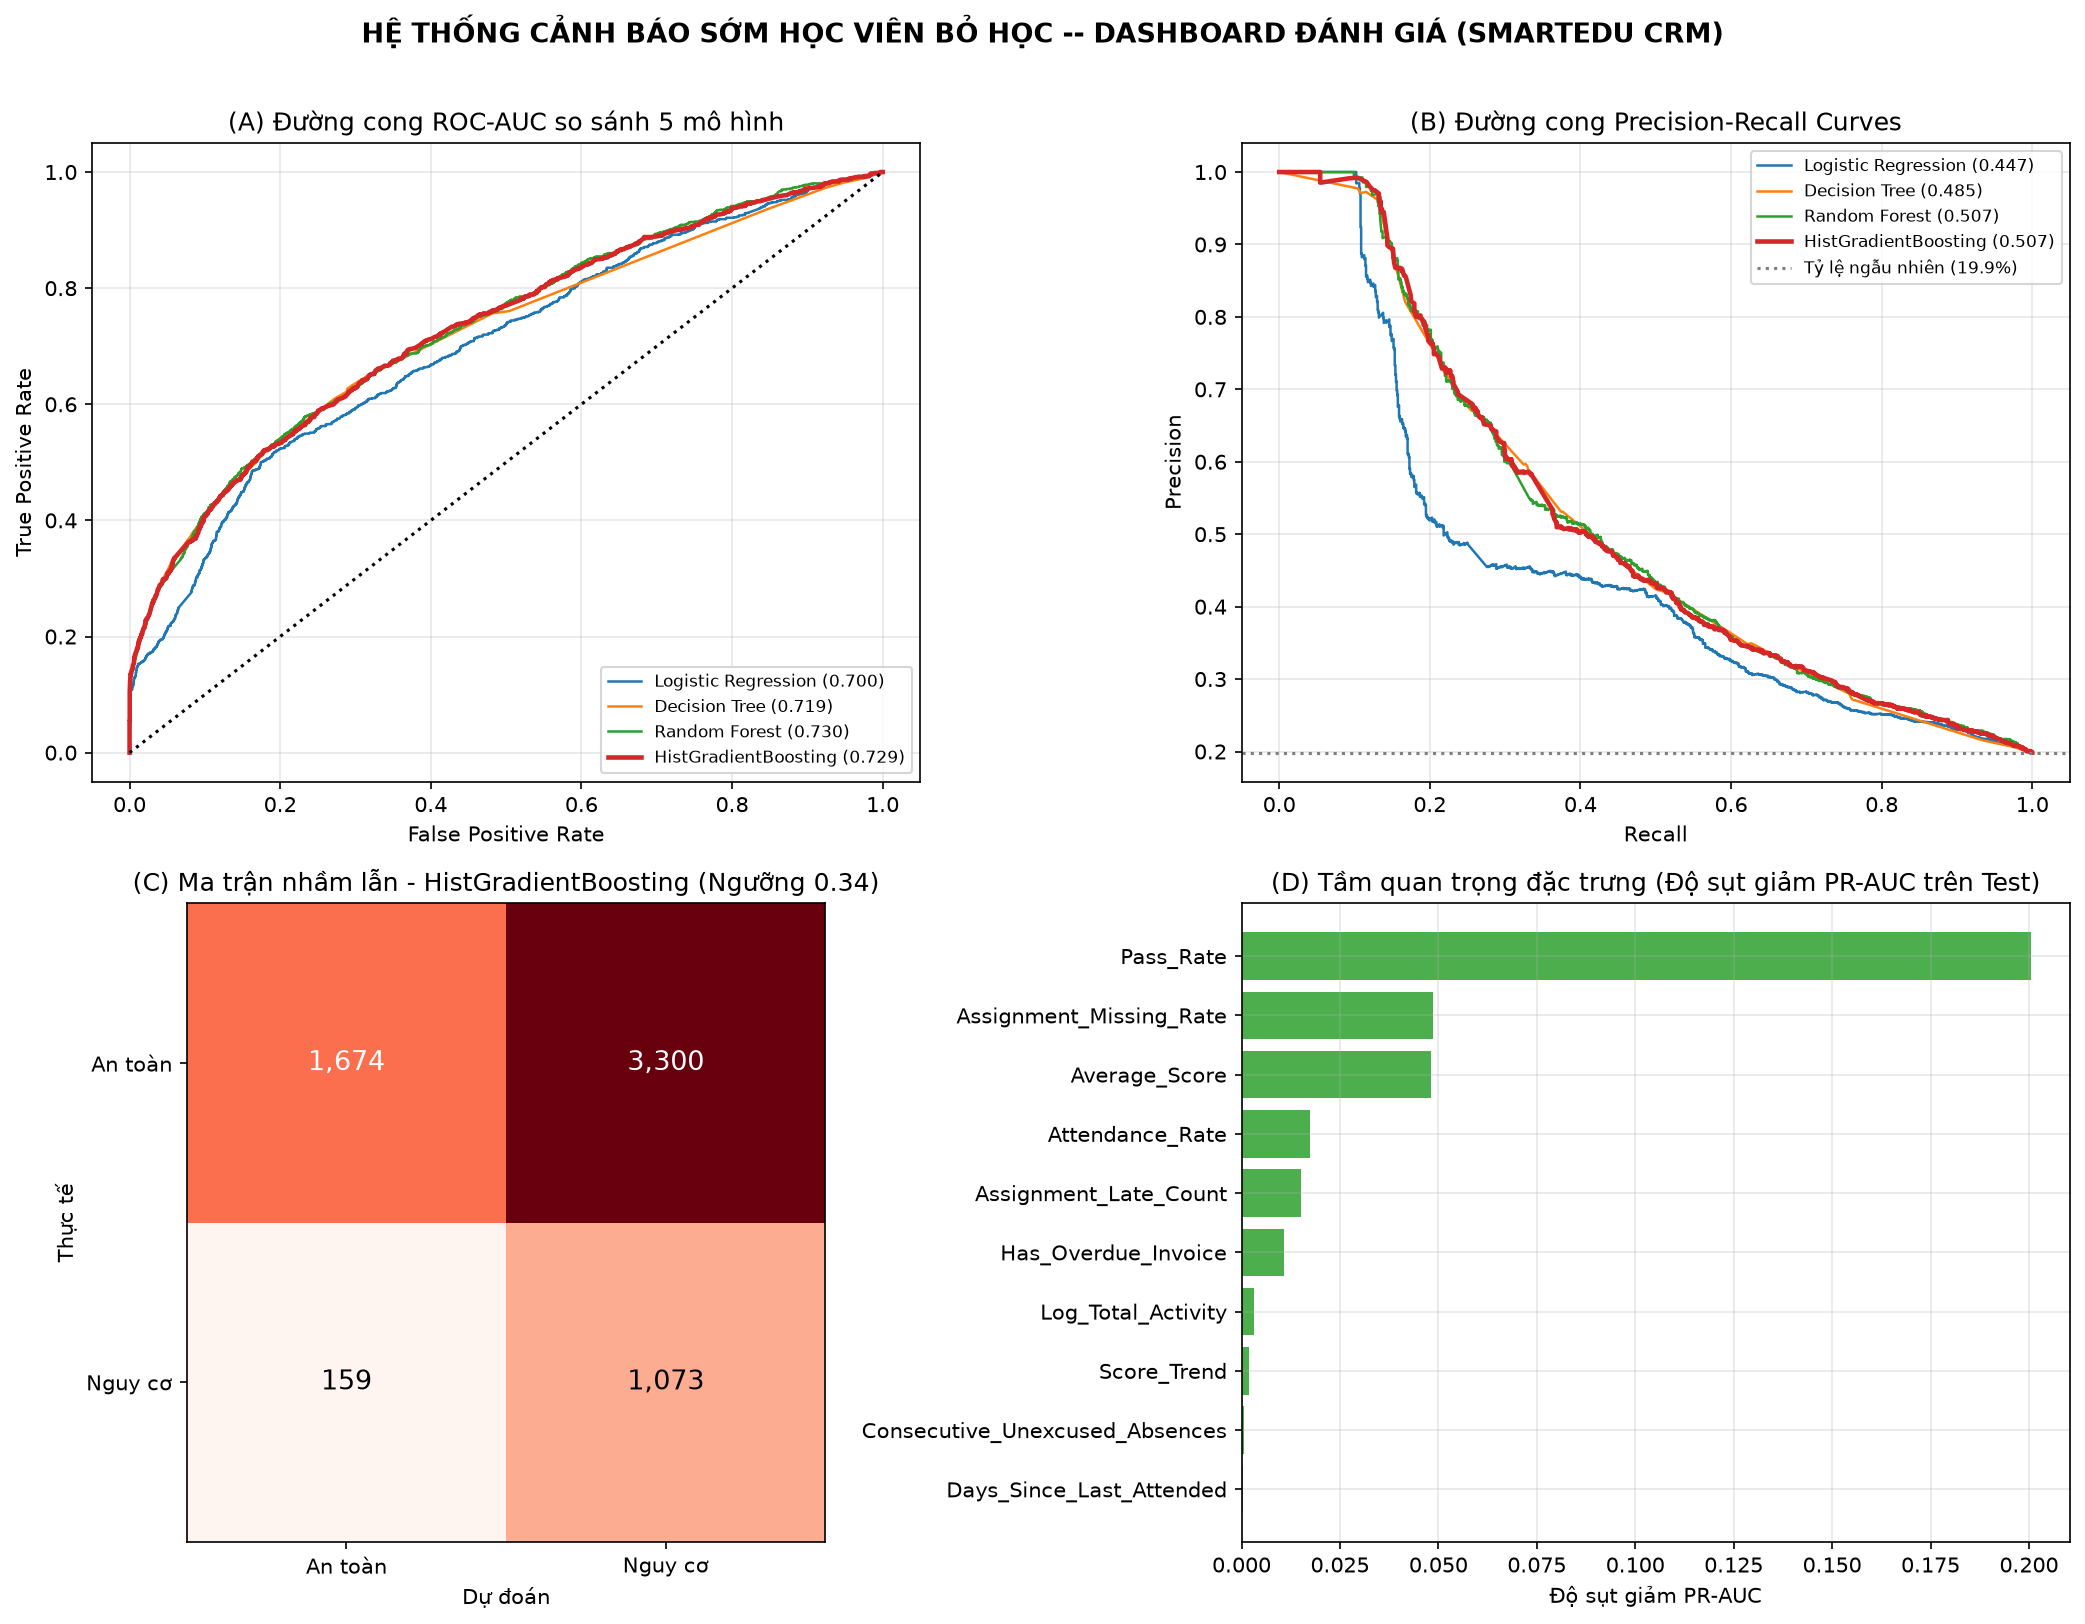

In [13]:
# Huấn luyện lại trên toàn bộ 30.944 bản ghi
final_pipe = make_pipeline(clone(model_zoo()[best_name]), FEATURE_COLS).fit(final_df[FEATURE_COLS], final_df[TARGET_COL])

bundle = {
    'pipeline': final_pipe,
    'features': FEATURE_COLS,
    'threshold': best_thr,
    'model_name': best_name,
    'version': 'v3',
    'milestones': {'UCI': 'end of semester 1', 'OULAD': f'day {CUTOFF_DAY}'},
    'note': 'Pipeline chuẩn chống rò rỉ dữ liệu, tối ưu F2-score giữ chân học viên cho SmartEdu CRM.'
}

export_path = os.path.join(CURRENT_DIR, 'dropout_model_v3_bundle.pkl')
joblib.dump(bundle, export_path)
print(f"[SUCCESS] Đã xuất bản Model Bundle hoàn tất tại:\n >> {export_path}")

In [16]:
# 1. Cài đặt thư viện nbconvert vào môi trường ảo
%pip install nbconvert

# 2. Xuất file notebook ra HTML
!jupyter nbconvert --to html Dropout_Risk_Model_v3_Training.ipynb



Note: you may need to restart the kernel to use updated packages.


[NbConvertApp] Converting notebook Dropout_Risk_Model_v3_Training.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 802336 bytes to Dropout_Risk_Model_v3_Training.html
